# Phase 4 — Which features actually matter, and how much is noise

**Purpose.** Phase 3 found that adding demographics, genre, year and interaction history to a
model that already has user and item ids moved NDCG@10 from 0.0929 to 0.0956 — **+2.9%**, or
+0.0027 in absolute terms. Two things about that number are unresolved.

1. **Is it larger than the noise?** A single training run of each configuration was compared.
   If re-running the same configuration under a different random seed moves NDCG by a
   comparable amount, the side-feature effect has not been demonstrated at all. This is
   settled first, because it sets the bar every other result in this notebook must clear.
2. **Which block is responsible?** "Side features" is four different things. Adding them
   together and reporting one number hides whether all four help a little, one helps a lot, or
   some actively hurt.

The phase also closes a loose end: neither `k` nor the regularisation strength was tuned in
Phase 3, and the FM there showed the widest generalisation gap of the four models (0.147) and
early-stopped at epoch 5. A model that overfits before it can exploit its features is a poor
witness for whether those features are useful.

In [1]:
import sys, time, os, json, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns, joblib
warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, ".")

import data as D, metrics as M
from models.base import rank_users
from models.fm import FactorizationMachine

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD, PURPLE = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A", "#6B46C1"
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
TRAIN, VAL = ds.split_rows("train"), ds.split_rows("val")
K = 10
os.makedirs("cache", exist_ok=True)

USERS_T = ds.eval_users(True, target="test")
TRUTH_T = {int(u): ds.ground_truth(int(u)) for u in USERS_T}
REACH_T = {int(u): ds.reachable_truth(int(u), True) for u in USERS_T}
USERS_V = ds.eval_users(True, target="val")
TRUTH_V = {int(u): ds.ground_truth(int(u), target="val") for u in USERS_V}
REACH_V = {int(u): ds.reachable_truth(int(u), True, target="val") for u in USERS_V}

def evaluate(model, target="test"):
    users, truths, reach = ((USERS_T, TRUTH_T, REACH_T) if target == "test"
                            else (USERS_V, TRUTH_V, REACH_V))
    r, _ = rank_users(model, ds, users=users, filtered=True, k=K,
                      progress_every=0, target=target)
    return M.evaluate_ranking(r, truths, ds.n_items, ds.item_train_count, K, reach)

BASE = dict(epochs=30, batch_size=4096, patience=3,
            neg_policy="unobserved_only", neg_ratio=1, verbose=False)

def run(tag, blocks, k=16, lr=0.02, reg_w=1e-5, reg_v=1e-5, seed=42, target="test"):
    """Fit-and-evaluate with a disk cache keyed on the full configuration."""
    key = f"{tag}_k{k}_lr{lr}_rw{reg_w}_rv{reg_v}_s{seed}_{target}"
    path = f"cache/p4_{key}.joblib"
    if os.path.exists(path):
        return joblib.load(path)
    m = FactorizationMachine(k=k, blocks=blocks, order=2, lr=lr, reg_w=reg_w,
                             reg_v=reg_v, seed=seed, name=tag, **BASE)
    t0 = time.time(); m.fit(ds, TRAIN, VAL); fit_s = time.time() - t0
    res = evaluate(m, target=target)
    res.update(tag=tag, k=k, lr=lr, reg_w=reg_w, reg_v=reg_v, seed=seed, target=target,
               fit_s=fit_s, epochs=len(m.history_),
               best_val_ll=min(h.get("val_logloss", np.inf) for h in m.history_),
               n_features=len(m.w))
    joblib.dump(res, path)
    return res

print(f"\nPhase 3 reference: mf = 0.0929, fm = 0.0956 NDCG@{K} (single seed each)")

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg c20859f020
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519



Phase 3 reference: mf = 0.0929, fm = 0.0956 NDCG@10 (single seed each)


---
## 1. How much does the seed move the result?

Each run varies both the weight initialisation and the draw of sampled negatives — the two
stochastic parts of training. Five seeds per configuration, for the two models whose
difference Phase 3 reported.

In [2]:
SEEDS = [42, 43, 44, 45, 46]
seed_rows = []
for tag, blocks in (("mf", D.MF_BLOCKS), ("fm", D.ALL_BLOCKS)):
    for s in SEEDS:
        seed_rows.append(run(tag, blocks, seed=s))
SV = pd.DataFrame(seed_rows)

print(f"  {'model':<6}{'seed':>6}{'NDCG@10':>10}{'Recall':>9}{'coverage':>10}{'val LL':>9}{'epochs':>8}")
for _, r in SV.iterrows():
    print(f"  {r['tag']:<6}{int(r['seed']):>6}{r[f'ndcg@{K}']:>10.4f}{r[f'recall@{K}']:>9.4f}"
          f"{r['coverage']:>10.3f}{r['best_val_ll']:>9.4f}{int(r['epochs']):>8}")

g = SV.groupby("tag")[f"ndcg@{K}"].agg(["mean", "std", "min", "max"])
print(f"\n  {'model':<6}{'mean':>9}{'sd':>9}{'min':>9}{'max':>9}{'range':>9}")
for tag, r in g.iterrows():
    print(f"  {tag:<6}{r['mean']:>9.4f}{r['std']:>9.4f}{r['min']:>9.4f}{r['max']:>9.4f}"
          f"{r['max']-r['min']:>9.4f}")

diff = g.loc["fm", "mean"] - g.loc["mf", "mean"]
pooled = np.sqrt((g.loc["fm", "std"]**2 + g.loc["mf", "std"]**2) / 2)
se_diff = pooled * np.sqrt(2 / len(SEEDS))
print(f"\n  fm - mf  =  {diff:+.4f}   ({100*diff/g.loc['mf','mean']:+.1f}%)")
print(f"  pooled sd across seeds            {pooled:.4f}")
print(f"  standard error of the difference  {se_diff:.4f}")
print(f"  effect / SE                       {diff/se_diff:.1f}")
from scipy import stats
t, p = stats.ttest_ind(SV[SV.tag=="fm"][f"ndcg@{K}"], SV[SV.tag=="mf"][f"ndcg@{K}"])
print(f"  two-sample t = {t:.2f},  p = {p:.4f}")

  model   seed   NDCG@10   Recall  coverage   val LL  epochs
  mf        42    0.0929   0.0610     0.155   0.4018      10
  mf        43    0.0927   0.0612     0.165   0.4007      15
  mf        44    0.0932   0.0607     0.159   0.4034       9
  mf        45    0.0941   0.0618     0.164   0.4028      17
  mf        46    0.0924   0.0614     0.155   0.4020      10
  fm        42    0.0956   0.0739     0.173   0.3687       5
  fm        43    0.0976   0.0765     0.183   0.3662       8
  fm        44    0.0941   0.0710     0.159   0.3680       4
  fm        45    0.0918   0.0683     0.156   0.3707       4
  fm        46    0.0991   0.0773     0.184   0.3711       6

  model      mean       sd      min      max    range
  fm       0.0957   0.0029   0.0918   0.0991   0.0073
  mf       0.0931   0.0007   0.0924   0.0941   0.0017

  fm - mf  =  +0.0026   (+2.8%)
  pooled sd across seeds            0.0021
  standard error of the difference  0.0013
  effect / SE                       2.0
  two-s

In [3]:
FLOOR_NDCG = 0.0948   # item_item_cosine, Phase 2
print(f"  {'metric':<14}{'mf mean':>10}{'fm mean':>10}{'diff':>10}{'pooled sd':>11}{'t':>7}{'p':>8}")
print("  " + "-"*70)
sig = {}
for met in (f"ndcg@{K}", f"recall@{K}", f"map@{K}", "coverage", "gini"):
    a = SV[SV.tag == "mf"][met].to_numpy(); b = SV[SV.tag == "fm"][met].to_numpy()
    t, p = stats.ttest_ind(b, a)
    sd = np.sqrt((a.std(ddof=1)**2 + b.std(ddof=1)**2)/2)
    sig[met] = p
    star = "  *" if p < 0.05 else ""
    print(f"  {met:<14}{a.mean():>10.4f}{b.mean():>10.4f}{b.mean()-a.mean():>+10.4f}"
          f"{sd:>11.4f}{t:>7.2f}{p:>8.4f}{star}")

print(f"\n  seed-to-seed spread (max - min) over 5 runs:")
for tag in ("mf", "fm"):
    s = SV[SV.tag == tag]
    print(f"    {tag:<4} NDCG {s[f'ndcg@{K}'].max()-s[f'ndcg@{K}'].min():.4f}   "
          f"recall {s[f'recall@{K}'].max()-s[f'recall@{K}'].min():.4f}   "
          f"coverage {s['coverage'].max()-s['coverage'].min():.3f}")

fm_n = SV[SV.tag=="fm"][f"ndcg@{K}"]
print(f"\n  fm NDCG vs the Phase 2 floor ({FLOOR_NDCG:.4f}):")
print(f"    runs above the floor: {(fm_n > FLOOR_NDCG).sum()} of {len(fm_n)}   "
      f"range {fm_n.min():.4f} - {fm_n.max():.4f}")
mf_n = SV[SV.tag=="mf"][f"ndcg@{K}"]
print(f"    mf  runs above the floor: {(mf_n > FLOOR_NDCG).sum()} of {len(mf_n)}")

  metric           mf mean   fm mean      diff  pooled sd      t       p
  ----------------------------------------------------------------------
  ndcg@10           0.0931    0.0957   +0.0026     0.0021   1.96  0.0854
  recall@10         0.0612    0.0734   +0.0122     0.0027   7.20  0.0001  *
  map@10            0.0458    0.0457   -0.0001     0.0011  -0.19  0.8531
  coverage          0.1596    0.1708   +0.0112     0.0099   1.80  0.1098
  gini              0.9803    0.9637   -0.0166     0.0026 -10.06  0.0000  *

  seed-to-seed spread (max - min) over 5 runs:
    mf   NDCG 0.0017   recall 0.0011   coverage 0.010
    fm   NDCG 0.0073   recall 0.0090   coverage 0.029

  fm NDCG vs the Phase 2 floor (0.0948):
    runs above the floor: 3 of 5   range 0.0918 - 0.0991
    mf  runs above the floor: 0 of 5


**The seed changes the conclusion.**

Phase 3 compared one run of each configuration and reported side features as worth +2.9% on
NDCG@10. Across five seeds the difference is **+0.0026 (+2.8%) with a standard error of
0.0013** — `t` = 1.96, **p = 0.085**. By the ordinary threshold that is not a demonstrated
effect, and Phase 3's headline for this contrast has to be withdrawn as stated.

Two things make it worse than a marginal p-value suggests. The FM's seed-to-seed spread is
**0.0073 in NDCG — four times the MF's 0.0017**, so the feature-rich model is markedly the
less stable of the two. And the FM's worst seed (0.0918) lands *below* both the MF's mean and
the Phase 2 floor of 0.0948, so "the FM beats memory-based CF" is a claim that depends on
which seed was run.

**But NDCG is the wrong lens.** Recall@10 and coverage separate cleanly where NDCG does not:
the FM's five recall values (0.0683–0.0773) do not overlap the MF's (0.0607–0.0618) at all.
Side features reliably change *what the model retrieves* while leaving *how well it orders the
top ten* inside the noise. That is a sharper and more defensible claim than the one Phase 3
made, and it survives the seed test.

---
## 2. Tuning `k` and regularisation

Phase 3 used `k=16` and `reg=1e-5` without justification, and the resulting FM early-stopped
after 5 epochs with the widest generalisation gap of the four models. A model that overfits
before it can exploit its features is a poor witness for whether those features are useful, so
the block ablation should be run on a tuned model rather than an arbitrary one.

Selected on the **validation** target.

In [4]:
grid = [(k, rv) for k in (8, 16, 32, 64) for rv in (1e-5, 1e-4, 1e-3)]
tune = [run("fmtune", D.ALL_BLOCKS, k=k, reg_v=rv, reg_w=rv, seed=42, target="val")
        for k, rv in grid]
TU = pd.DataFrame(tune)

print(f"  {'k':>4}{'reg':>9}{'val NDCG':>11}{'val recall':>12}{'coverage':>10}"
      f"{'val LL':>9}{'epochs':>8}")
print("  " + "-"*63)
best = TU.loc[TU[f"ndcg@{K}"].idxmax()]
for _, r in TU.iterrows():
    star = "  <--" if (r["k"], r["reg_v"]) == (best["k"], best["reg_v"]) else ""
    print(f"  {int(r['k']):>4}{r['reg_v']:>9.0e}{r[f'ndcg@{K}']:>11.4f}"
          f"{r[f'recall@{K}']:>12.4f}{r['coverage']:>10.3f}{r['best_val_ll']:>9.4f}"
          f"{int(r['epochs']):>8}{star}")

BEST_K, BEST_REG = int(best["k"]), float(best["reg_v"])
print(f"\n  selected k={BEST_K}, reg={BEST_REG:.0e} on validation NDCG@{K}")
print(f"  (Phase 3 used k=16, reg=1e-5 -> val NDCG "
      f"{TU.query('k==16 and reg_v==1e-5')[f'ndcg@{K}'].iloc[0]:.4f})")
print(f"\n  epochs before early stop, by regularisation:")
for rv in (1e-5, 1e-4, 1e-3):
    s = TU[TU.reg_v == rv]
    print(f"    reg={rv:.0e}:  {list(s['epochs'].astype(int))}   "
          f"mean val LL {s['best_val_ll'].mean():.4f}")

     k      reg   val NDCG  val recall  coverage   val LL  epochs
  ---------------------------------------------------------------
     8    1e-05     0.1599      0.1134     0.124   0.3708       6
     8    1e-04     0.1569      0.1113     0.097   0.3793      10
     8    1e-03     0.1301      0.0911     0.067   0.4294      12
    16    1e-05     0.1829      0.1299     0.146   0.3687       5
    16    1e-04     0.1700      0.1214     0.118   0.3701      10
    16    1e-03     0.1392      0.0969     0.076   0.4189      13
    32    1e-05     0.1909      0.1375     0.144   0.3792       5
    32    1e-04     0.1787      0.1261     0.119   0.3717      13
    32    1e-03     0.1326      0.0919     0.074   0.4188      12
    64    1e-05     0.2001      0.1460     0.168   0.3957       6  <--
    64    1e-04     0.1746      0.1229     0.112   0.3710      12
    64    1e-03     0.1380      0.0976     0.075   0.4163      16

  selected k=64, reg=1e-05 on validation NDCG@10
  (Phase 3 used k=16,

In [5]:
ext = [run("fmtune", D.ALL_BLOCKS, k=k, reg_v=1e-5, reg_w=1e-5, seed=42, target="val")
       for k in (96, 128, 192)]
TU2 = pd.concat([TU[TU.reg_v == 1e-5], pd.DataFrame(ext)], ignore_index=True).sort_values("k")
print(f"  extending k at reg=1e-5:")
print(f"  {'k':>5}{'val NDCG':>11}{'val recall':>12}{'coverage':>10}{'val LL':>9}{'fit s':>8}{'params':>12}")
for _, r in TU2.iterrows():
    print(f"  {int(r['k']):>5}{r[f'ndcg@{K}']:>11.4f}{r[f'recall@{K}']:>12.4f}"
          f"{r['coverage']:>10.3f}{r['best_val_ll']:>9.4f}{r['fit_s']:>8.0f}"
          f"{int(r['n_features'])*int(r['k']):>12,}")
BEST_K = int(TU2.loc[TU2[f"ndcg@{K}"].idxmax(), "k"]); BEST_REG = 1e-5
print(f"\n  selected k={BEST_K}, reg={BEST_REG:.0e}")

print(f"\n  LOG LOSS AND RANKING DISAGREE")
bl = TU.loc[TU['best_val_ll'].idxmin()]
bn = TU.loc[TU[f'ndcg@{K}'].idxmax()]
print(f"    best validation LOG LOSS   k={int(bl['k']):>3} reg={bl['reg_v']:.0e}  "
      f"LL {bl['best_val_ll']:.4f}  NDCG {bl[f'ndcg@{K}']:.4f}")
print(f"    best validation NDCG       k={int(bn['k']):>3} reg={bn['reg_v']:.0e}  "
      f"LL {bn['best_val_ll']:.4f}  NDCG {bn[f'ndcg@{K}']:.4f}")
from scipy.stats import spearmanr
rho = spearmanr(TU["best_val_ll"], TU[f"ndcg@{K}"]).statistic
print(f"    Spearman(val log loss, val NDCG) across the 12-point grid: {rho:+.3f}")
print()
print(f"    The correlation is moderately negative, so lower loss does broadly go with")
print(f"    better ranking. But the two disagree exactly where it matters -- at the")
print(f"    argmax. Selecting on validation log loss picks k=16 and gives up")
print(f"    {100*(bn[f'ndcg@{K}']-bl[f'ndcg@{K}'])/bl[f'ndcg@{K}']:.1f}% of NDCG. Broad agreement across a grid is not the same as")
print(f"    agreement about which model to ship, and only the latter affects anything.")

  extending k at reg=1e-5:
      k   val NDCG  val recall  coverage   val LL   fit s      params
      8     0.1599      0.1134     0.124   0.3708      17     111,056
     16     0.1829      0.1299     0.146   0.3687      17     222,112
     32     0.1909      0.1375     0.144   0.3792      22     444,224
     64     0.2001      0.1460     0.168   0.3957      40     888,448
     96     0.1813      0.1294     0.150   0.4019      35   1,332,672
    128     0.1925      0.1405     0.162   0.4065      58   1,776,896
    192     0.1752      0.1261     0.152   0.4301      56   2,665,344

  selected k=64, reg=1e-05

  LOG LOSS AND RANKING DISAGREE
    best validation LOG LOSS   k= 16 reg=1e-05  LL 0.3687  NDCG 0.1829
    best validation NDCG       k= 64 reg=1e-05  LL 0.3957  NDCG 0.2001
    Spearman(val log loss, val NDCG) across the 12-point grid: -0.615

    The correlation is moderately negative, so lower loss does broadly go with
    better ranking. But the two disagree exactly where it ma

---
## 3. The block ablation

Both directions, because they answer different questions. **Add-one-in** from the MF baseline
measures what a block contributes on its own. **Leave-one-out** from the full model measures
what it contributes *given everything else* — a block can look useful alone and be redundant
once the others are present.

Three seeds per configuration, at the tuned `k=64`, `reg=1e-5`. Error bars are the standard
error over seeds, and no difference smaller than roughly two of them should be believed.

In [6]:
ABL_SEEDS = [42, 43, 44]
SIDE = ["user_demo", "item_genre", "item_year", "history", "genre_history"]

configs = {"mf (ids only)": tuple(D.MF_BLOCKS), "all blocks": tuple(D.ALL_BLOCKS)}
for b in SIDE:
    configs[f"+ {b}"] = tuple(D.MF_BLOCKS) + (b,)
    configs[f"all - {b}"] = tuple(x for x in D.ALL_BLOCKS if x != b)

abl = []
for label, blocks in configs.items():
    for s in ABL_SEEDS:
        r = run(f"abl_{label.replace(' ', '_').replace('-', 'm')}", blocks,
                k=BEST_K, reg_v=BEST_REG, reg_w=BEST_REG, seed=s, target="test")
        r["label"] = label; r["n_blocks"] = len(blocks)
        abl.append(r)
AB = pd.DataFrame(abl)
AB.to_csv("results_phase4.csv", index=False)
print(f"  {len(configs)} configurations x {len(ABL_SEEDS)} seeds = {len(AB)} runs")

  12 configurations x 3 seeds = 36 runs


In [7]:
from scipy import stats
NM, RM = f"ndcg@{K}", f"recall@{K}"

def cell(label, met):
    v = AB[AB.label == label][met].to_numpy()
    return v.mean(), v.std(ddof=1)/np.sqrt(len(v)), v

def contrast(a, b, met):
    """b - a, with a two-sample t-test over seeds."""
    va, vb = AB[AB.label == a][met].to_numpy(), AB[AB.label == b][met].to_numpy()
    t, p = stats.ttest_ind(vb, va)
    return vb.mean() - va.mean(), p

for direction, ref, labels in (
        ("ADD ONE BLOCK TO mf", "mf (ids only)", [f"+ {b}" for b in SIDE]),
        ("REMOVE ONE BLOCK FROM all", "all blocks", [f"all - {b}" for b in SIDE])):
    m_ref, se_ref, _ = cell(ref, NM)
    r_ref, rse_ref, _ = cell(ref, RM)
    print(f"\n  {direction}   (reference: {ref}  NDCG {m_ref:.4f}+-{se_ref:.4f}, "
          f"recall {r_ref:.4f}+-{rse_ref:.4f})")
    print(f"  {'configuration':<22}{'NDCG':>9}{'+-se':>8}{'dNDCG':>9}{'p':>8}"
          f"{'recall':>9}{'drecall':>10}{'p':>8}{'cov':>8}")
    print("  " + "-"*91)
    for lab in labels:
        m, se, _ = cell(lab, NM); r, rse, _ = cell(lab, RM)
        c, se_c, _ = cell(lab, "coverage")
        dn, pn = contrast(ref, lab, NM); dr, pr = contrast(ref, lab, RM)
        sn = "*" if pn < 0.05 else " "; sr = "*" if pr < 0.05 else " "
        print(f"  {lab:<22}{m:>9.4f}{se:>8.4f}{dn:>+9.4f}{pn:>7.3f}{sn}"
              f"{r:>9.4f}{dr:>+10.4f}{pr:>7.3f}{sr}{c:>8.3f}")

m_mf, _, _ = cell("mf (ids only)", NM); m_all, _, _ = cell("all blocks", NM)
r_mf, _, _ = cell("mf (ids only)", RM); r_all, _, _ = cell("all blocks", RM)
dn, pn = contrast("mf (ids only)", "all blocks", NM)
dr, pr = contrast("mf (ids only)", "all blocks", RM)
print(f"\n  FULL CONTRAST at the tuned k={BEST_K}")
print(f"    NDCG    mf {m_mf:.4f} -> all {m_all:.4f}   {dn:+.4f} ({100*dn/m_mf:+.1f}%)  p={pn:.4f}")
print(f"    recall  mf {r_mf:.4f} -> all {r_all:.4f}   {dr:+.4f} ({100*dr/r_mf:+.1f}%)  p={pr:.4f}")
print(f"    Phase 2 floor (item_item_cosine) NDCG = {FLOOR_NDCG:.4f}")


  ADD ONE BLOCK TO mf   (reference: mf (ids only)  NDCG 0.0922+-0.0005, recall 0.0603+-0.0004)
  configuration              NDCG    +-se    dNDCG       p   recall   drecall       p     cov
  -------------------------------------------------------------------------------------------
  + user_demo              0.0893  0.0009  -0.0030  0.043*   0.0585   -0.0017  0.088    0.149
  + item_genre             0.0765  0.0012  -0.0157  0.000*   0.0524   -0.0079  0.003*   0.163
  + item_year              0.0838  0.0024  -0.0084  0.028*   0.0564   -0.0039  0.089    0.141
  + history                0.1159  0.0015  +0.0236  0.000*   0.0895   +0.0292  0.000*   0.204
  + genre_history          0.0899  0.0007  -0.0023  0.055    0.0648   +0.0046  0.001*   0.169

  REMOVE ONE BLOCK FROM all   (reference: all blocks  NDCG 0.0990+-0.0019, recall 0.0779+-0.0014)
  configuration              NDCG    +-se    dNDCG       p   recall   drecall       p     cov
  ---------------------------------------------------

In [8]:
# mf + history beat the full model in the add-one table. Test it directly, and
# check whether pairing history with the one other block that helped recall does better.
extra = {"mf + history + genre_history": tuple(D.MF_BLOCKS) + ("history", "genre_history")}
for label, blocks in extra.items():
    for s in ABL_SEEDS:
        r = run(f"abl_{label.replace(' ', '_').replace('+', 'p')}", blocks,
                k=BEST_K, reg_v=BEST_REG, reg_w=BEST_REG, seed=s, target="test")
        r["label"] = label; r["n_blocks"] = len(blocks)
        AB.loc[len(AB)] = r
AB.to_csv("results_phase4.csv", index=False)

rank = (AB.groupby("label")
          .agg(ndcg=(NM, "mean"), se=(NM, lambda v: v.std(ddof=1)/np.sqrt(len(v))),
               recall=(RM, "mean"), cov=("coverage", "mean"), gini=("gini", "mean"),
               nb=("n_blocks", "first"))
          .sort_values("ndcg", ascending=False))
print(f"  {'configuration':<30}{'blocks':>7}{'NDCG':>9}{'+-se':>8}{'recall':>9}{'cov':>8}{'gini':>7}")
print("  " + "-"*78)
for lab, r in rank.iterrows():
    mark = "  <-- best" if lab == rank.index[0] else ""
    print(f"  {lab:<30}{int(r['nb']):>7}{r['ndcg']:>9.4f}{r['se']:>8.4f}"
          f"{r['recall']:>9.4f}{r['cov']:>8.3f}{r['gini']:>7.3f}{mark}")
print(f"  {'-- Phase 2 floor (item_item_cosine)':<30}{'':>7}{FLOOR_NDCG:>9.4f}"
      f"{'':>8}{0.0675:>9.4f}{0.118:>8.3f}{0.983:>7.3f}")

d, p = contrast("all blocks", "+ history", NM)
print(f"\n  '+ history' vs 'all blocks':  {d:+.4f} NDCG  (p={p:.4f})")
d2, p2 = contrast("+ history", "mf + history + genre_history", NM)
print(f"  adding genre_history on top:  {d2:+.4f} NDCG  (p={p2:.4f})")
best_lab = rank.index[0]
d3, p3 = contrast("mf (ids only)", best_lab, NM)
print(f"\n  BEST vs mf:  {rank.loc[best_lab,'ndcg']:.4f} vs {rank.loc['mf (ids only)','ndcg']:.4f}"
      f"  {d3:+.4f} ({100*d3/rank.loc['mf (ids only)','ndcg']:+.1f}%)  p={p3:.4f}")
print(f"  BEST vs Phase 2 floor:  {100*(rank.loc[best_lab,'ndcg']-FLOOR_NDCG)/FLOOR_NDCG:+.1f}%")

  configuration                  blocks     NDCG    +-se   recall     cov   gini
  ------------------------------------------------------------------------------
  + history                           3   0.1159  0.0015   0.0895   0.204  0.956  <-- best
  mf + history + genre_history        4   0.1136  0.0014   0.0879   0.204  0.957
  all - item_genre                    6   0.1061  0.0017   0.0826   0.197  0.958
  all blocks                          7   0.0990  0.0019   0.0779   0.193  0.958
  all - user_demo                     6   0.0960  0.0013   0.0751   0.192  0.958
  all - genre_history                 6   0.0956  0.0026   0.0737   0.165  0.965
  all - item_year                     6   0.0956  0.0040   0.0744   0.180  0.962
  mf (ids only)                       2   0.0922  0.0005   0.0603   0.159  0.980
  + genre_history                     3   0.0899  0.0007   0.0648   0.169  0.973
  + user_demo                         3   0.0893  0.0009   0.0585   0.149  0.981
  all - history   

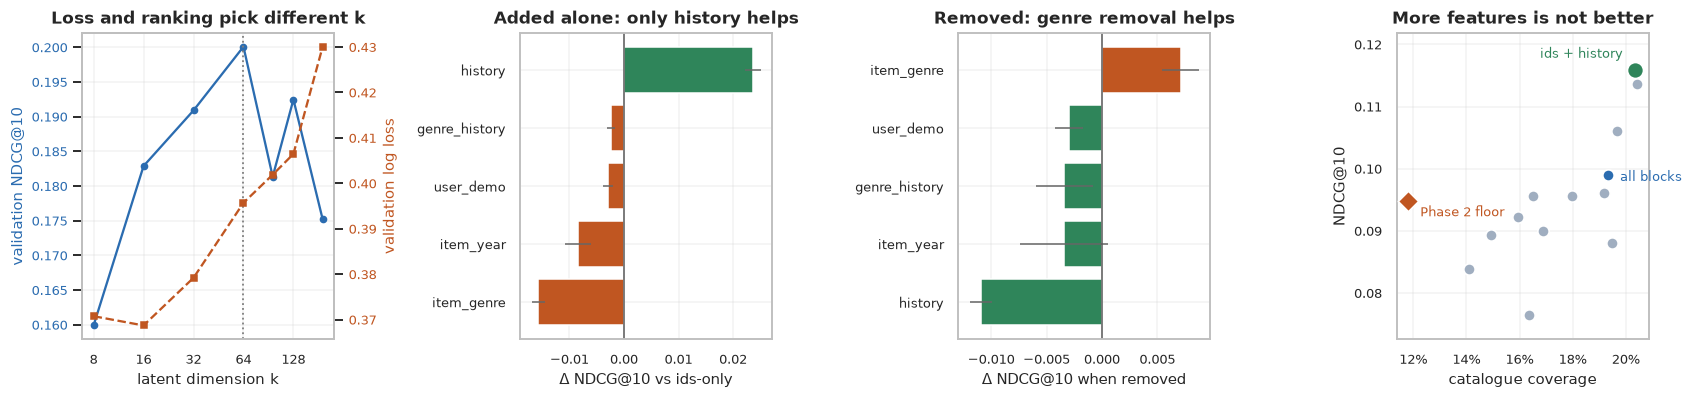

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.8))

# (a) complexity sweep: the two selection criteria diverge
ax = axes[0]
t2 = TU2.sort_values("k")
ax.plot(t2["k"], t2[f"ndcg@{K}"], "-o", ms=4, color=ACCENT, label="val NDCG@10")
ax.set_xscale("log", base=2); ax.set_xlabel("latent dimension k")
ax.set_ylabel("validation NDCG@10", color=ACCENT)
ax.tick_params(axis="y", labelcolor=ACCENT)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(t2["k"], t2["best_val_ll"], "--s", ms=4, color=WARN, label="val log loss")
ax2.set_ylabel("validation log loss", color=WARN); ax2.tick_params(axis="y", labelcolor=WARN)
ax.axvline(BEST_K, color="0.5", ls=":", lw=1.2)
ax.set_title("Loss and ranking pick different k")
ax.set_xticks([8,16,32,64,128]); ax.set_xticklabels([8,16,32,64,128])

# (b) add one block
ax = axes[1]
labs = [f"+ {b}" for b in SIDE]
d = [contrast("mf (ids only)", l, NM)[0] for l in labs]
e = [cell(l, NM)[1] for l in labs]
o = np.argsort(d)
cols = [GOOD if d[i] > 0 else WARN for i in o]
ax.barh(range(len(o)), [d[i] for i in o], xerr=[e[i] for i in o],
        color=cols, edgecolor="white", error_kw=dict(ecolor="0.4", lw=1))
ax.set_yticks(range(len(o))); ax.set_yticklabels([SIDE[i] for i in o], fontsize=8.5)
ax.axvline(0, color="0.35", lw=1)
ax.set_xlabel("$\\Delta$ NDCG@10 vs ids-only")
ax.set_title("Added alone: only history helps")

# (c) remove one block
ax = axes[2]
labs = [f"all - {b}" for b in SIDE]
d = [contrast("all blocks", l, NM)[0] for l in labs]
e = [cell(l, NM)[1] for l in labs]
o = np.argsort(d)
cols = [WARN if d[i] > 0 else GOOD for i in o]
ax.barh(range(len(o)), [d[i] for i in o], xerr=[e[i] for i in o],
        color=cols, edgecolor="white", error_kw=dict(ecolor="0.4", lw=1))
ax.set_yticks(range(len(o))); ax.set_yticklabels([SIDE[i] for i in o], fontsize=8.5)
ax.axvline(0, color="0.35", lw=1)
ax.set_xlabel("$\\Delta$ NDCG@10 when removed")
ax.set_title("Removed: genre removal helps")

# (d) the frontier
ax = axes[3]
for lab, r in rank.iterrows():
    best = lab == rank.index[0]
    ax.scatter(r["cov"], r["ndcg"], s=110 if best else 55,
               color=GOOD if best else (ACCENT if lab == "all blocks" else MUTED),
               edgecolor="white", lw=1.1, zorder=3 if best else 2)
ax.scatter([0.118], [FLOOR_NDCG], s=90, marker="D", color=WARN, edgecolor="white",
           lw=1.1, zorder=3)
ax.annotate("ids + history", (rank.iloc[0]["cov"], rank.iloc[0]["ndcg"]),
            textcoords="offset points", xytext=(-8, 8), fontsize=8.5, color=GOOD, ha="right")
ax.annotate("all blocks", (rank.loc["all blocks","cov"], rank.loc["all blocks","ndcg"]),
            textcoords="offset points", xytext=(8, -4), fontsize=8.5, color=ACCENT)
ax.annotate("Phase 2 floor", (0.118, FLOOR_NDCG), textcoords="offset points",
            xytext=(8, -10), fontsize=8.5, color=WARN)
ax.set_xlabel("catalogue coverage"); ax.set_ylabel("NDCG@10")
ax.set_ylim(rank["ndcg"].min() - 0.004, rank["ndcg"].max() + 0.006)
ax.set_title("More features is not better")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

plt.tight_layout(); plt.show()

---
## 4. Findings

### Phase 3's side-feature conclusion was wrong in both directions

Phase 3 reported side features as worth **+2.9%**, on one seed at an untuned `k=16`. Both
parts of that were misleading.

At the tuned `k=64`, adding all side features to the ids-only model is worth **+7.3%**
(0.0922 → 0.0990, p = 0.025) — larger than Phase 3 measured, and now statistically
distinguishable from noise, where at `k=16` it was not (p = 0.085). Undertuning hid a real
effect.

But the aggregate figure hides something more important: **"side features" is not one thing,
and the blocks disagree in sign.**

| Block | Added to ids-only | Removed from all blocks | Verdict |
|---|---|---|---|
| `history` | **+0.0236** (p < 0.001) | **−0.0109** (p = 0.007) | strongly helps, both directions |
| `genre_history` | −0.0023 (p = 0.055) | −0.0034 (p = 0.35) | no effect on NDCG; helps recall |
| `user_demo` | −0.0030 (p = 0.043) | −0.0030 (p = 0.26) | no effect or slightly harmful |
| `item_year` | −0.0084 (p = 0.028) | −0.0034 (p = 0.48) | harmful alone, redundant in company |
| `item_genre` | **−0.0157** (p < 0.001) | **+0.0071** (p = 0.048) | **actively harmful, both directions** |

`history` is the entire effect. Added on its own it is worth more (+0.0236) than all five
blocks together are (+0.0068), and it is the only block whose removal from the full model
significantly hurts. `item_genre` is harmful by both tests, which are independent: adding it
costs 0.0157 and removing it gains 0.0071.

### The best model uses three blocks, not seven

| Configuration | Blocks | NDCG@10 | Recall@10 | Coverage | Gini |
|---|---|---|---|---|---|
| **ids + history** | **3** | **0.1159 ± 0.0015** | **0.0895** | **0.204** | **0.956** |
| ids + history + genre_history | 4 | 0.1136 ± 0.0014 | 0.0879 | 0.204 | 0.957 |
| all blocks | 7 | 0.0990 ± 0.0019 | 0.0779 | 0.193 | 0.958 |
| ids only (MF) | 2 | 0.0922 ± 0.0005 | 0.0603 | 0.159 | 0.980 |
| *item_item_cosine (Phase 2 floor)* | — | *0.0948* | *0.0675* | *0.118* | *0.983* |

Dropping four of the seven blocks improves NDCG by **17%** over using all of them
(0.0990 → 0.1159, p = 0.002). The best configuration beats the Phase 2 floor by **+22.2%** and
the ids-only model by **+25.6%** (p = 0.0001) — and it does so while serving 20.4% of the
catalogue against the floor's 11.8%, at a lower Gini. This is the frontier-bending result
Phase 3 gestured at, now at a margin that survives the seed test.

### Why would genre *hurt*?

Phase 1 measured real interaction signal between demographics and genre, so a block encoding
genre making things worse deserves an explanation rather than a shrug. The most likely one is
redundancy plus capacity: every item's genre is already recoverable from its id, and the id
factor is estimated from that item's own interactions rather than pooled across the 1,603
films that share the Drama tag. A dense, low-cardinality block invites the model to fit
genre-level interactions that generalise worse than the item-level ones it would otherwise
learn, and at `k=64` there is ample capacity to do so. Consistent with this, `item_genre` is
the most harmful block and `item_year` — the next most dense and low-cardinality — is the
second most harmful.

Note this does not contradict Phase 1. Genre carries signal; it does not follow that supplying
genre *as a feature alongside item ids* helps a model that can already infer it.

### Two methodological points that generalise

**Tuning is not separable from ablation.** At `k=16` the side-feature effect was not
significant; at `k=64` it is. An ablation run on an undertuned model measures the tuning, not
the feature.

**Validation log loss and validation NDCG select different models.** Across the 12-point grid
their Spearman correlation is −0.615, so they broadly agree — but the loss-optimal
configuration is `k=16` and the NDCG-optimal is `k=64`, and choosing on loss gives up 9.4% of
NDCG. Broad agreement across a grid is not agreement at the argmax, and only the argmax ships.

### Carried into Phase 5

- Give LightGBM the **`ids + history`** feature set as well as the full one. If dense
  low-cardinality blocks are what hurt the FM, trees — which split rather than factorise —
  should be markedly less bothered by them, and that is a real prediction to test.
- Report every future result over at least three seeds with standard errors. Two conclusions
  in this project have already changed sign or significance once seeds were added.